<a href="https://colab.research.google.com/github/varxnn7/character-consistency/blob/main/strategy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q controlnet_aux
!pip install -q diffusers transformers accelerate opencv-python Pillow
print("ControlNet environment ready!")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 290.4/290.4 kB 5.1 MB/s eta 0:00:00
ControlNet environment ready!


In [ ]:
import os
from google.colab import files

os.makedirs("data/inputs", exist_ok=True)
os.makedirs("data/outputs", exist_ok=True)

print("--- Upload Subject Image ---")
uploaded_sub = files.upload()
for fn in uploaded_sub.keys():
    os.rename(fn, "data/inputs/subject.png")
    break

print("\n--- Upload Garment Image ---")
uploaded_gar = files.upload()
for fn in uploaded_gar.keys():
    os.rename(fn, "data/inputs/garment.png")
    break

print("Images successfully uploaded to data/inputs/!")

--- Upload Subject Image ---


Saving subject.png to subject.png

--- Upload Garment Image ---


Saving 1.png to 1.png
Images successfully uploaded to data/inputs/!


Loading Fashion Segmentation Model on cpu...


preprocessor_config.json:   0%|          | 0.00/372 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/2.93k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  189MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/644 [00:00<?, ?it/s]

Clean dilated mask saved to data/inputs/mask.png!


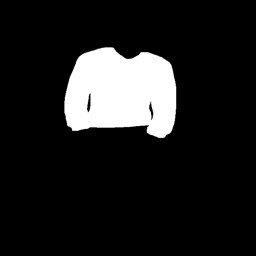

In [ ]:
import torch
import cv2
import numpy as np
from PIL import Image
from transformers import AutoImageProcessor, AutoModelForSemanticSegmentation

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Loading Fashion Segmentation Model on {device}...")

processor = AutoImageProcessor.from_pretrained("sayeed99/segformer-b3-fashion")
model = AutoModelForSemanticSegmentation.from_pretrained("sayeed99/segformer-b3-fashion").to(device)

image = Image.open("data/inputs/subject.png").convert("RGB")
inputs = processor(images=image, return_tensors="pt").to(device)

with torch.no_grad():
    outputs = model(**inputs)
    logits = outputs.logits.cpu()

upsampled_logits = torch.nn.functional.interpolate(
    logits,
    size=image.size[::-1],
    mode="bilinear",
    align_corners=False,
)
pred_seg = upsampled_logits.argmax(dim=1)[0].numpy()

mask_np = np.zeros(pred_seg.shape, dtype=np.uint8)

for lbl in np.unique(pred_seg):
    if lbl == 0:
        continue
    binary = (pred_seg == lbl).astype(np.uint8)
    y_indices = np.where(binary > 0)[0]
    if len(y_indices) > 500:
        mean_y = np.mean(y_indices) / image.size[1]
        if 0.20 <= mean_y <= 0.60:
            mask_np = np.maximum(mask_np, binary * 255)

# Boundary halo khatam karne ke liye slight dilation
kernel = np.ones((7, 7), np.uint8)
dilated_mask = cv2.dilate(mask_np, kernel, iterations=2)

mask_img = Image.fromarray(dilated_mask).convert("L")
mask_img.save("data/inputs/mask.png")
print("Clean dilated mask saved to data/inputs/mask.png!")

mask_img.resize((256, 256))

/usr/local/lib/python3.13/dist-packages/controlnet_aux/mediapipe_face/mediapipe_face_common.py:7: UserWarning: The module 'mediapipe' is not installed. The package will have limited functionality. Please install it using the command: pip install 'mediapipe'
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.13/dist-packages/timm/models/registry.py:4: FutureWarning: Importing from timm.models.registry is deprecated, please import via timm.models
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.models", FutureWarning)
/usr/local/lib/python3.13/dist-packages/controlnet_aux/segment_anything/modeling/tiny_vit_sam.py:654: UserWarning: Overwriting tiny_vit_5m_224 in registry with controlnet_aux.segmen

Loading ControlNet + Inpainting Pipeline on cpu...


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/999 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B / 1.45GB            

...

annotator/ckpts/hand_pose_model.pth: downloading bytes:           |  0.00B            

facenet.pth: reconstructing file:   0%|          |  0.00B /  154MB            

facenet.pth: downloading bytes:           |  0.00B            

  0%|          | 0/15 [00:00<?, ?it/s]

Try-On with ControlNet Pose & Face preservation complete!


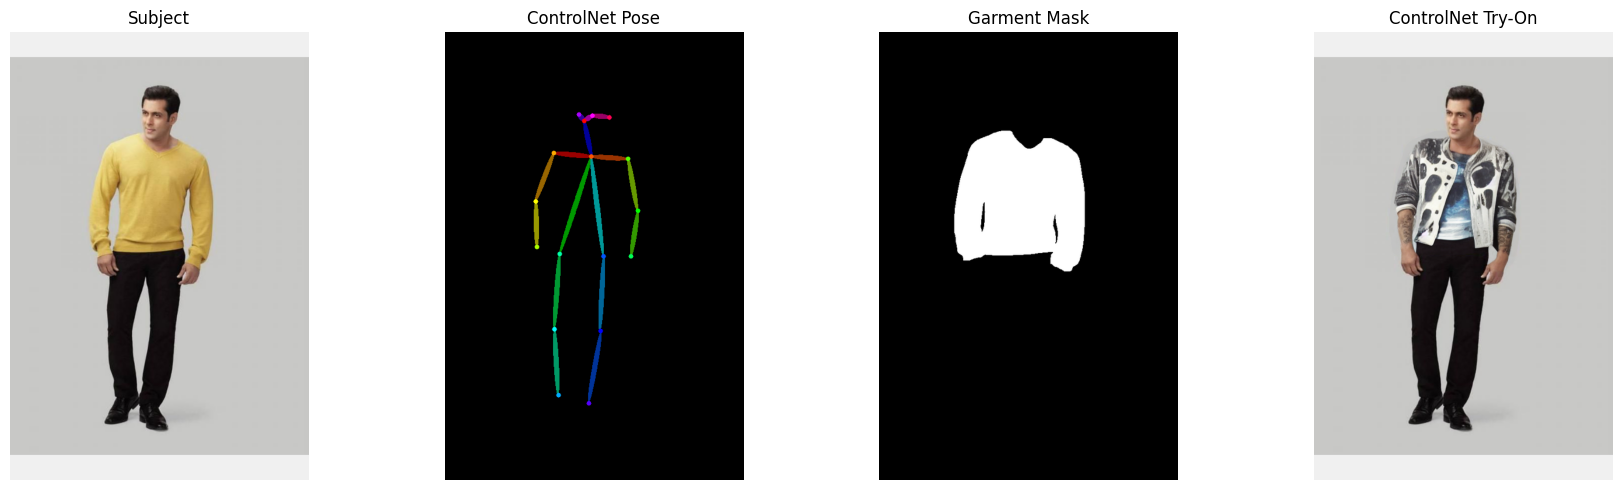

In [ ]:
import torch
import cv2
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

from controlnet_aux import OpenposeDetector
from diffusers import StableDiffusionControlNetInpaintPipeline, ControlNetModel

device = "cuda" if torch.cuda.is_available() else "cpu"
torch_dtype = torch.float16 if device == "cuda" else torch.float32

print(f"Loading ControlNet + Inpainting Pipeline on {device}...")

# 1. Load ControlNet OpenPose to freeze body posture & width
controlnet = ControlNetModel.from_pretrained(
    "lllyasviel/control_v11p_sd15_openpose",
    torch_dtype=torch_dtype
).to(device)

pipe = StableDiffusionControlNetInpaintPipeline.from_pretrained(
    "runwayml/stable-diffusion-inpainting",
    controlnet=controlnet,
    torch_dtype=torch_dtype,
    safety_checker=None
).to(device)

# Load IP-Adapter for garment reference
pipe.load_ip_adapter(
    "h94/IP-Adapter",
    subfolder="models",
    weight_name="ip-adapter_sd15.bin"
)
pipe.set_ip_adapter_scale(0.80)

# 2. Aspect Ratio Preserving Resizer (Skinny issue fix)
def letterbox_image(img, target_size=(512, 768)):
    w, h = img.size
    target_w, target_h = target_size
    scale = min(target_w / w, target_h / h)
    new_w, new_h = int(w * scale), int(h * scale)
    resized = img.resize((new_w, new_h), Image.Resampling.LANCZOS)

    canvas = Image.new(img.mode, target_size, (0 if img.mode == "L" else (240, 240, 240)))
    pad_x = (target_w - new_w) // 2
    pad_y = (target_h - new_h) // 2
    canvas.paste(resized, (pad_x, pad_y))
    return canvas

subject_orig = Image.open("data/inputs/subject.png").convert("RGB")
garment_orig = Image.open("data/inputs/garment.png").convert("RGB")
mask_orig = Image.open("data/inputs/mask.png").convert("L")

TARGET_SIZE = (512, 768)
subject_img = letterbox_image(subject_orig, TARGET_SIZE)
garment_img = letterbox_image(garment_orig, TARGET_SIZE)
mask_img = letterbox_image(mask_orig, TARGET_SIZE)

# 3. OpenPose skeleton extraction
openpose = OpenposeDetector.from_pretrained("lllyasviel/ControlNet")
pose_image = openpose(subject_img)

generator = torch.Generator(device=device).manual_seed(42)

# 4. Inpaint with ControlNet Pose guidance
result = pipe(
    prompt="a male model wearing a blue jacket, natural body proportions, photorealistic, studio photography, 8k",
    negative_prompt="skinny, narrow shoulders, thin body, distorted limbs, altered face, extra arms",
    image=subject_img,
    mask_image=mask_img,
    control_image=pose_image,
    ip_adapter_image=garment_img,
    num_inference_steps=25 if device == "cuda" else 15,
    controlnet_conditioning_scale=0.9,
    guidance_scale=7.5,
    generator=generator
).images[0]

# 5. Composite Original Face & Background (Zero face drift)
result_np = np.array(result)
subject_np = np.array(subject_img)
mask_np = np.array(mask_img) / 255.0
mask_3ch = np.stack([mask_np] * 3, axis=-1)

final_np = (result_np * mask_3ch + subject_np * (1.0 - mask_3ch)).astype(np.uint8)
final_img = Image.fromarray(final_np)
final_img.save("data/outputs/tryon_result.png")
print("Try-On with ControlNet Pose & Face preservation complete!")

# Display
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
axes[0].imshow(subject_img); axes[0].set_title("Subject"); axes[0].axis("off")
axes[1].imshow(pose_image); axes[1].set_title("ControlNet Pose"); axes[1].axis("off")
axes[2].imshow(mask_img, cmap="gray"); axes[2].set_title("Garment Mask"); axes[2].axis("off")
axes[3].imshow(final_img); axes[3].set_title("ControlNet Try-On"); axes[3].axis("off")
plt.tight_layout()
plt.show()